# Step 35: Error analysis: predicted vs true engagement (review E16)
The best final model (dense head on w2v-BERT 2.0 + VideoMAE + context), ONE seed, trained on the 6 speaker-independent folds; every window is predicted by a model that never saw that person. (Mean fold CCC 0.739 for this seed; the 5-seed result is 0.767.)
*This notebook only loads the saved results of `src/35_error_analysis.py`; it does not train anything and needs no NoXi data.*

**In short** (what this notebook shows)

- **What:** Error analysis (review E16): predicted vs true engagement for the best and worst sessions.
- **Needs the NoXi data?** No: it loads reports/error_analysis_*.csv and the saved charts (made by src/35_error_analysis.py).
- **Result / use:** Best sessions CCC about 0.90 (German, French), worst about 0.45 (English); the prediction under-estimates the peaks.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option('display.width', 220)

**Per session** (sorted by CCC).

In [4]:
es = pd.read_csv('reports/error_analysis_sessions.csv', dtype={'session': str})
print(es.round(3).to_string(index=False))
print()
print('mean session CCC by language:', es.groupby('language').ccc.mean().round(3).to_dict())

session language  windows   ccc   mae   bias  mean_true  std_true  std_pred
    072   German     1738 0.910 0.047 -0.004      0.577     0.155     0.118
    070   German     2086 0.908 0.050 -0.038      0.634     0.164     0.147
    007   French     4344 0.901 0.057 -0.022      0.633     0.177     0.152
    068   German     2020 0.887 0.045 -0.020      0.613     0.136     0.105
    001   French     2130 0.844 0.081  0.057      0.590     0.203     0.168
    075   German     1990 0.828 0.054 -0.047      0.577     0.120     0.097
    021   French     1730 0.814 0.083  0.078      0.557     0.155     0.150
    076   German     1002 0.798 0.041  0.009      0.515     0.096     0.066
    013   French     2708 0.739 0.071 -0.044      0.616     0.144     0.094
    063  English     1278 0.736 0.089 -0.046      0.529     0.174     0.119
    074   German     1908 0.733 0.056 -0.044      0.551     0.103     0.086
    058  English     3020 0.716 0.064 -0.014      0.525     0.089     0.115
    020   Fr

**By true engagement level.** Low values are over-predicted and high values under-predicted (binning by the true value shows some of this for any noisy predictor).

In [5]:
print(pd.read_csv('reports/error_analysis_levels.csv').round(3).to_string(index=False))

                                                        level  windows  mean_true  mean_pred   mae   bias
                                             low (true < 0.4)     3600      0.308      0.427 0.128  0.119
                                          middle (0.4 to 0.7)    35030      0.542      0.522 0.059 -0.020
                                           high (true >= 0.7)     9856      0.794      0.709 0.103 -0.085
all (slope of truth on prediction = 0.95; 1.0 would be ideal)    48486      0.576      0.553 0.073 -0.023


**True (black) and predicted (grey) engagement: the 2 best and the 2 worst sessions.**

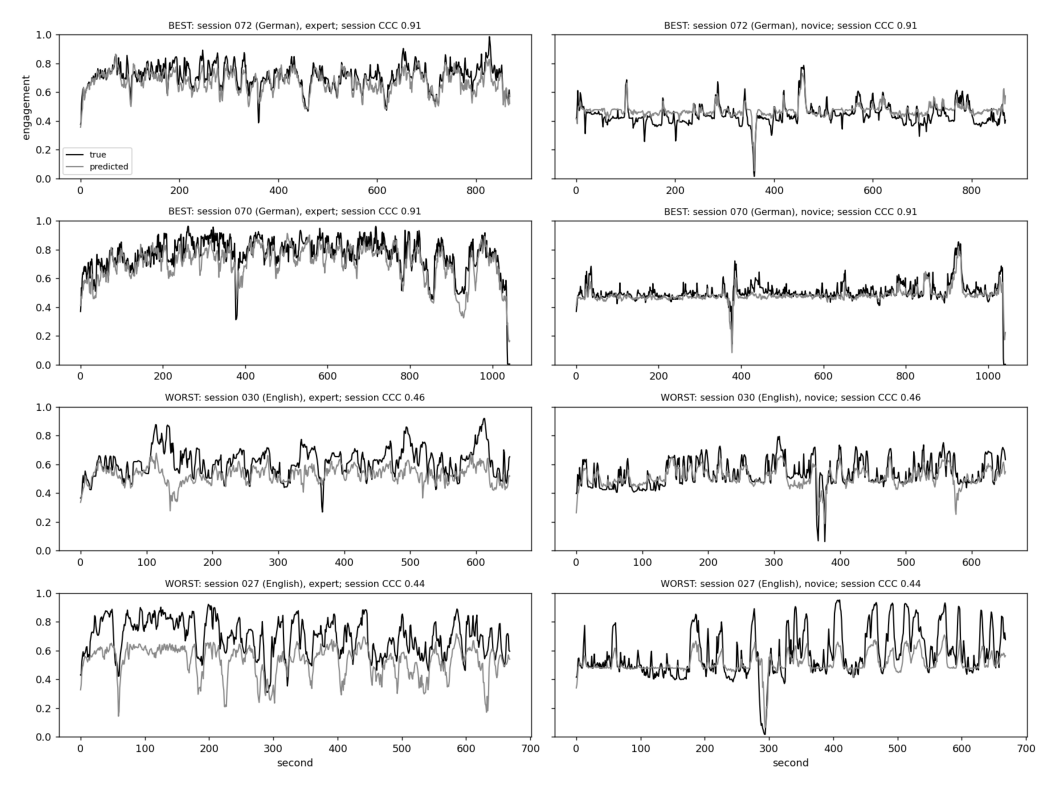

In [6]:
plt.figure(figsize=(14, 10)); plt.imshow(mpimg.imread('charts/error_analysis_timelines.png')); plt.axis('off'); plt.show()

**All windows: predicted against true.**

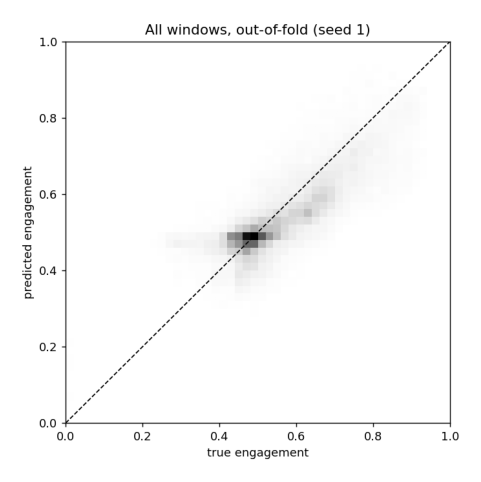

In [7]:
plt.figure(figsize=(6, 6)); plt.imshow(mpimg.imread('charts/error_analysis_scatter.png')); plt.axis('off'); plt.show()

**Reading.** The best sessions (German 072 and 070, French 007) reach CCC about 0.90 and the prediction follows the dips and rises closely; the worst (English 027 and 030, French 014) are about 0.44-0.50, where the prediction follows the direction of the changes but under-predicts the peaks. The mean session CCC is German 0.80, French 0.70, English 0.60, the same order as the language test.